1/10,000 = 0.001 = 0.1%

Diseño del estudio y aprobacion etica.
Sleccion del modelo bilogico.
Exposicion controlada a la sustancia.
Evaluacion de respuestas fisiologicas y bioquimicas.
Analisis estadistico e interpretacion.

AI = Simulacion del pensamiento humano.
ML = Aprendisaje de la maquina. (Reglas de como aprender)
DL = Como aprende la maquina. (Datos de los cuales aprende)

L.Quimico <--> L.Natural
Comunicacion (Humano <--> Maquina)
Molecula/SMILES

Etiqueta -> Que propiedad tiene

14GB ram.


In [8]:
pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 37.1 MB/s  0:00:00


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [11]:
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator, Draw
from sklearn.model_selection import train_test_split
from rdkit import RDLogger

In [12]:
RDLogger.DisableLog('rdApp.*')

In [19]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [20]:
print(tf.__version__)

2.21.0


In [37]:
URL ='https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz'
df=pd.read_csv(URL,compression='gzip')
endpoint='NR-AR'

print('Dimensiones originales:',df.shape)
print('Columnas:',df.columns.tolist())

Dimensiones originales: (7831, 14)
Columnas: ['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53', 'mol_id', 'smiles']


In [42]:
display(df[['smiles',endpoint]].head())

print('Etiquetas incluyendo ausentes:')
print(df[endpoint].value_counts(dropna=False))

,smiles,NR-AR
0,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0
1,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,NaN
3,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
4,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0


Etiquetas incluyendo ausentes:
NR-AR
0.0    6956
NaN     566
1.0     309
Name: count, dtype: int64


In [53]:
data = df[['smiles', endpoint]].dropna().copy()
data = data[data[endpoint].isin([0, 1])].copy()

def canonicalize(s):
    try:
        mol = Chem.MolFromSmiles(str(s))
        return Chem.MolToSmiles(mol, canonical=True) if mol is not None else None
    except Exception:
        return None

data['canonical_smiles'] = data['smiles'].map(canonicalize)
data = data.dropna(subset=['canonical_smiles'])
conflicts = data.groupby('canonical_smiles')[endpoint].nunique()
ambiguous = set(conflicts[conflicts > 1].index)

print('Estructuras con etiquetas contradictorias excluidas:', len(ambiguous))

data = data[~data['canonical_smiles'].isin(ambiguous)]
data = data.drop_duplicates(subset='canonical_smiles').reset_index(drop=True)
data['label'] = data[endpoint].astype(int)

print('Moléculas únicas:', len(data))
print(data['label'].value_counts())

assert data['label'].nunique() == 2, 'Se requieren ambas clases.'

Estructuras con etiquetas contradictorias excluidas: 0
Moléculas únicas: 7258
label
0    6950
1     308
Name: count, dtype: int64


SMILES: CCOc1ccc2nc(S(N)(=O)=O)sc2c1


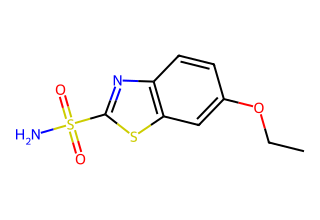

Matriz X: (7258, 1024) | Etiquetas y: (7258,)
Bits encendidos en primera molécula: 36


In [60]:
ejemplo = data.loc[0, 'canonical_smiles']

print('SMILES:', ejemplo)
display(Draw.MolToImage(Chem.MolFromSmiles(ejemplo), size=(320, 220)))

N_BITS = 1024
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=N_BITS)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    fp = generator.GetFingerprint(mol)
    arr = np.zeros((N_BITS,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr.astype(np.float32)

X = np.stack([smiles_to_fingerprint(s) for s in data['canonical_smiles']])
y = data['label'].to_numpy(dtype=np.int32)
print('Matriz X:', X.shape, '| Etiquetas y:', y.shape)
print('Bits encendidos en primera molécula:', int(X[0].sum()))

In [47]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)

In [48]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

In [49]:
for name, labels in [('Entrenamiento (Train)', y_train), ('Validación (Validation)', y_val), ('Prueba (Test)', y_test)]:
    print(f'{name}: {len(labels)} moléculas | Moléculas tóxicas: {labels.mean():.2%}')

Entrenamiento (Train): 5080 moléculas | Moléculas tóxicas: 4.25%
Validación (Validation): 1089 moléculas | Moléculas tóxicas: 4.22%
Prueba (Test): 1089 moléculas | Moléculas tóxicas: 4.22%
